Dataset shape (samples, features): (569, 30)
Class names: ['malignant' 'benign']
Number of class 0 (malignant): 212
Number of class 1 (benign):    357

Train size: 398
Test size: 171

Base (Single) Models

Model: Logistic Regression
  Train Accuracy: 0.9648
  Test  Accuracy: 0.9415

Model: Decision Tree
  Train Accuracy: 1.0000
  Test  Accuracy: 0.9181


c:\Users\shaha\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Model: KNN (k=5)
  Train Accuracy: 0.9497
  Test  Accuracy: 0.9240

Ensemble Models

Model: Bagging (Decision Tree)
  Train Accuracy: 0.9975
  Test  Accuracy: 0.9532

Model: Random Forest
  Train Accuracy: 1.0000
  Test  Accuracy: 0.9357

Model: Extra Trees
  Train Accuracy: 1.0000
  Test  Accuracy: 0.9708

Model: AdaBoost
  Train Accuracy: 1.0000
  Test  Accuracy: 0.9532

Model: Gradient Boosting
  Train Accuracy: 1.0000
  Test  Accuracy: 0.9474

Model: Voting Ensemble (soft)
  Train Accuracy: 0.9899
  Test  Accuracy: 0.9357


c:\Users\shaha\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\shaha\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_


Model: Stacking Ensemble
  Train Accuracy: 0.9849
  Test  Accuracy: 0.9415


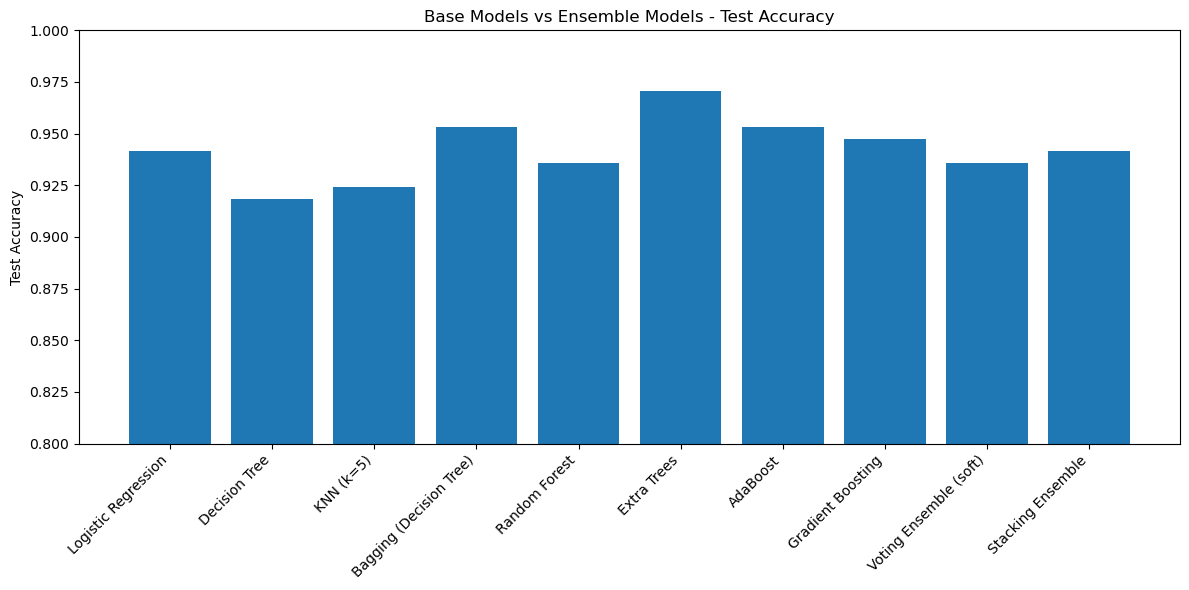


Detailed Classification Report for Best Ensemble: Extra Trees
              precision    recall  f1-score   support

   malignant       0.98      0.94      0.96        64
      benign       0.96      0.99      0.98       107

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171


Top 10 important features for Extra Trees
worst perimeter: 0.097
worst radius: 0.088
worst concave points: 0.084
worst area: 0.077
mean radius: 0.064
mean concavity: 0.063
mean concave points: 0.062
mean perimeter: 0.055
mean area: 0.049
worst concavity: 0.045


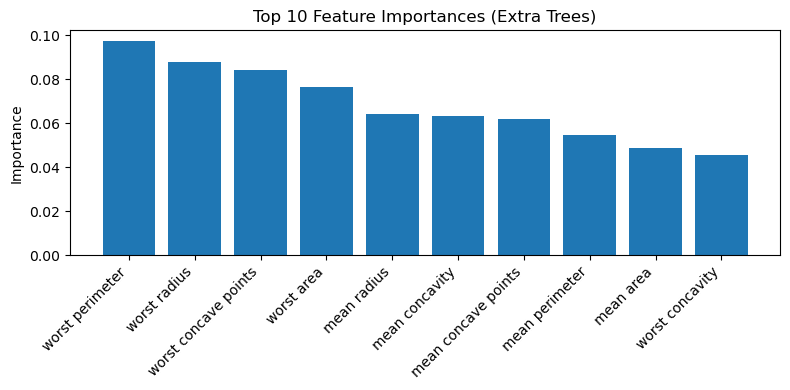


Hyperparameter Demo: Random Forest n_estimators
n_estimators =  10 -> CV mean accuracy = 0.9549 ± 0.0257
n_estimators =  50 -> CV mean accuracy = 0.9625 ± 0.0353
n_estimators = 100 -> CV mean accuracy = 0.9725 ± 0.0330
n_estimators = 200 -> CV mean accuracy = 0.9675 ± 0.0322

Demo complete! 🎉


In [1]:
# ===============================
# Ensemble Learning Demo (Colab)
# ===============================
# This script demonstrates:
# - Single ("base") models
# - Bagging
# - Random Forest
# - Extra Trees
# - Boosting (AdaBoost, Gradient Boosting)
# - Voting Ensemble
# - Stacking Ensemble
#
# Dataset: Breast Cancer (binary classification)
# Library: scikit-learn
# This is designed for class demonstration with explanations.

# ---- 1. Imports ----
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report

# Base models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Ensemble models
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

# For visualization (optional, but nice for class)
import matplotlib.pyplot as plt


# ---- 2. Load and inspect the dataset ----
# Breast cancer dataset: features = tumor measurements, target = benign/malignant
data = load_breast_cancer()
X = data.data        # features (numeric)
y = data.target      # labels (0 = malignant, 1 = benign)

print("Dataset shape (samples, features):", X.shape)
print("Class names:", data.target_names)
print("Number of class 0 (malignant):", np.sum(y == 0))
print("Number of class 1 (benign):   ", np.sum(y == 1))


# ---- 3. Train-test split ----
# We keep a part of the data (30%) as test set to evaluate generalization.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y  # keeps class proportion similar in train and test
)

print("\nTrain size:", X_train.shape[0])
print("Test size:", X_test.shape[0])


# ---- 4. Define base (non-ensemble) models ----
# These are simple models we'll compare to ensembles.
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "Decision Tree":       DecisionTreeClassifier(random_state=42),
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5)
}


# ---- 5. Define ensemble models ----

# 5.1 Bagging
# Bagging = Bootstrap Aggregating: train many models on random subsets of data & features.

bagging_dt = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),  # UPDATED
    n_estimators=50,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    random_state=42
)

# 5.4 AdaBoost (Updated)
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),  # UPDATED
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# 5.2 Random Forest
# Special case of bagging with decision trees where each split considers random features.
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

# 5.3 Extra Trees (Extremely Randomized Trees)
# Like RandomForest but with more randomness in split selection.
extra_trees = ExtraTreesClassifier(
    n_estimators=100,
    random_state=42
)

# 5.4 AdaBoost (Adaptive Boosting)
# Sequentially focuses on the mistakes of previous models.
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# 5.5 Gradient Boosting
# Builds trees sequentially to reduce the loss (gradient descent in function space).
gboost = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# 5.6 Voting Ensemble
# Combines different types of models and takes a majority vote (hard) or average of probabilities (soft).
voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=500, random_state=42)),
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ],
    voting="soft"  # "soft" uses predicted probabilities, often better than "hard"
)

# 5.7 Stacking Ensemble
# Uses predictions of base models as new features for a final “meta-model”.
stacking = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=500, random_state=42)),
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=5))
    ],
    final_estimator=RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    passthrough=False  # if True, original features are concatenated with meta-features
)


ensemble_models = {
    "Bagging (Decision Tree)": bagging_dt,
    "Random Forest":           rf,
    "Extra Trees":             extra_trees,
    "AdaBoost":                ada,
    "Gradient Boosting":       gboost,
    "Voting Ensemble (soft)":  voting,
    "Stacking Ensemble":       stacking
}


# ---- 6. Train and evaluate all models ----
def evaluate_models(models_dict, X_train, X_test, y_train, y_test, title="Model Comparison"):
    """
    Train each model in models_dict, print accuracy on train and test sets,
    and return a dictionary of test accuracies.
    """
    test_scores = {}
    print("\n" + "="*60)
    print(title)
    print("="*60)

    for name, model in models_dict.items():
        model.fit(X_train, y_train)
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)

        train_acc = accuracy_score(y_train, y_pred_train)
        test_acc = accuracy_score(y_test, y_pred_test)
        test_scores[name] = test_acc

        print(f"\nModel: {name}")
        print(f"  Train Accuracy: {train_acc:.4f}")
        print(f"  Test  Accuracy: {test_acc:.4f}")

    return test_scores


# Evaluate base models
base_scores = evaluate_models(
    base_models,
    X_train, X_test, y_train, y_test,
    title="Base (Single) Models"
)

# Evaluate ensemble models
ensemble_scores = evaluate_models(
    ensemble_models,
    X_train, X_test, y_train, y_test,
    title="Ensemble Models"
)


# ---- 7. Compare results in a bar chart ----
# This visualization helps show how ensembles often outperform single models.
all_scores = {**base_scores, **ensemble_scores}  # merge dictionaries

plt.figure(figsize=(12, 6))
plt.bar(range(len(all_scores)), list(all_scores.values()))
plt.xticks(range(len(all_scores)), list(all_scores.keys()), rotation=45, ha="right")
plt.ylabel("Test Accuracy")
plt.title("Base Models vs Ensemble Models - Test Accuracy")
plt.ylim(0.8, 1.0)  # adjust based on dataset; here we know accuracies are high
plt.tight_layout()
plt.show()


# ---- 8. Show detailed report for one model ----
# For teaching, it's useful to show a classification report for a chosen model.
best_model_name = max(ensemble_scores, key=ensemble_scores.get)
best_model = ensemble_models[best_model_name]
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("\n" + "="*60)
print(f"Detailed Classification Report for Best Ensemble: {best_model_name}")
print("="*60)
print(classification_report(y_test, y_pred, target_names=data.target_names))


# ---- 9. (Optional) Feature importance for tree-based ensemble ----
# Many tree ensembles give feature_importances_ to show which features matter.
if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
    indices = np.argsort(importances)[::-1][:10]  # top 10 features

    print("\nTop 10 important features for", best_model_name)
    for idx in indices:
        print(f"{data.feature_names[idx]}: {importances[idx]:.3f}")

    plt.figure(figsize=(8, 4))
    plt.bar(range(len(indices)), importances[indices])
    plt.xticks(range(len(indices)), [data.feature_names[i] for i in indices],
               rotation=45, ha="right")
    plt.ylabel("Importance")
    plt.title(f"Top 10 Feature Importances ({best_model_name})")
    plt.tight_layout()
    plt.show()


# ---- 10. (Optional) Quick hyperparameter demo for Random Forest ----
# Show how changing n_estimators affects performance using cross-validation.
print("\n" + "="*60)
print("Hyperparameter Demo: Random Forest n_estimators")
print("="*60)

estimator_values = [10, 50, 100, 200]
for n in estimator_values:
    rf_temp = RandomForestClassifier(n_estimators=n, random_state=42)
    cv_scores = cross_val_score(rf_temp, X_train, y_train, cv=5)
    print(f"n_estimators = {n:3d} -> CV mean accuracy = {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")


print("\nDemo complete! 🎉")
